# Combined features, hourly 72h forecast, 2015–2024 (FD11)

Forecasts `SWC_20` (soil water content at 20 cm) at station `FD11` **72 hours** after the end of a 48-hour input
window, with the best features from the `feature_testing_ppt*` notebooks combined. It compares the model with the
naive baselines (last value, 24h moving average).

Two feature sets are trained and tested:

- **base:** `SWC_20`, `Ppt_sum_log_24h`
- **combined:** base + `T_5_mean_24h`, day of year (`doy_sin`, `doy_cos`), `SWC_5`, `SWC_20_below_max_72h`

The plots show the combined model.

| | |
|---|---|
| Data | `TxSON33_modeling_complete.parquet`, station `FD11`, hourly |
| Split | train 2015–2021 (7 years), validation 2022 (early stopping only), test 2024; 2023 skipped (rain gauge outage) |
| Target | `SWC_20` exactly 72 h after the window's last hour; only `observed` readings are used as targets or scored |
| Network output | the change in `SWC_20` from the window's last hour, added back to that last value |
| Model | `model_test`'s BiLSTM (2 layers, hidden size 64, dropout 0.2); Huber loss (δ 0.005); Adam lr 1e-3; batch size 32; stride 8 for training and validation windows; up to 30 epochs, patience 10; seed 42. No cross-validation or tuning |
| Baselines | last value (persistence) and 24h moving average, scored on exactly the same targets |
| Data caveat | `SWC_5` and `T_5` behave differently in 2015–2016: `SWC_5` drops to 0.014 (never below 0.095 from 2017) and `T_5` reaches 58 °C (at most 49 °C from 2017). Both years are in the training set |

In [8]:
# --- Setup and reproducibility ---
import hashlib
import os
import random
import urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

# The repo root holds the parquet. If it is not found (e.g. on Colab), it is downloaded next to this notebook.
PARQUET_PATH = "../TxSON33_modeling_complete.parquet"
PARQUET_URL = ("https://raw.githubusercontent.com/AkhilJar/tx-soil-moisture/a61427b2c1f45fb1a607f2b9aa2c73cc2aa32701/"
               "datasets/txson33_complete_for_modeling/TxSON33_modeling_complete.parquet")
PARQUET_SHA256 = "c7b71436bcd201e097fefc7f4a4efc20366d0642e2c16566dfc595b0f91af4c9"

STATION = "FD11"
TRAIN_YEARS = list(range(2015, 2022))   # 2015-2021
VAL_YEARS, TEST_YEARS = [2022], [2024]  # 2023 skipped (rain gauge outage)
WINDOW_SIZE = 48           # hours of past data used as input
HORIZON = 72               # target = SWC_20 this many hours after the window's last hour
TRAINING_STRIDE = 8
VALIDATION_STRIDE = 8
BATCH_SIZE = 32
EPOCHS = 30
PATIENCE = 10
LR = 1e-3
PPT_DEADBAND_MM = 1.0      # hourly rain below 1 mm is set to 0 before the rain total
HUBER_DELTA = 0.005        # SWC_20 units
TARGET = "SWC_20"

BASE_FEATURES = ["SWC_20", "Ppt_sum_log_24h"]
FEATURE_SETS = {
    "base": BASE_FEATURES,
    "combined": BASE_FEATURES + ["T_5_mean_24h", "doy_sin", "doy_cos", "SWC_5", "SWC_20_below_max_72h"],
}
ALL_FEATURES = FEATURE_SETS["combined"]
PLOT_SET = "combined"      # the feature set shown in the plots

OUTPUT_DIR = "outputs_combined_10yr"
os.makedirs(OUTPUT_DIR, exist_ok=True)
# Plot colors: actual = ink, model = blue, last-value baseline = orange, reference lines = gray
C_ACTUAL, C_MODEL, C_LAST, C_MUTED = "#0b0b0b", "#2a78d6", "#eb6834", "#8a8984"

device: cuda


## 1. Data and features

Every feature at hour *t* uses data at or before *t* only. Features are computed on the full `FD11` history (from
2014-11), so the 24h features are complete from 2015-01-01.

- `Ppt_sum_log_24h`: `log1p` of the rain over the last 24 h, after setting hourly rain below 1 mm to 0.
- `T_5_mean_24h`: mean soil temperature at 5 cm over the last 24 h.
- `doy_sin`, `doy_cos`: day of year as a circle, so 31 Dec and 1 Jan are neighbours. It is known in advance.
- `SWC_20_below_max_72h`: `SWC_20` minus its maximum over the last 72 h (≤ 0), i.e. how far the soil has drained since its recent peak.

In [9]:
if not os.path.exists(PARQUET_PATH):
    PARQUET_PATH = "TxSON33_modeling_complete.parquet"
    if not os.path.exists(PARQUET_PATH):
        print("parquet not found; downloading it from GitHub (84.5 MB) ...")
        urllib.request.urlretrieve(PARQUET_URL, PARQUET_PATH + ".part")
        with open(PARQUET_PATH + ".part", "rb") as f:
            assert hashlib.sha256(f.read()).hexdigest() == PARQUET_SHA256, "downloaded file does not match the dataset"
        os.replace(PARQUET_PATH + ".part", PARQUET_PATH)
raw = pd.read_parquet(PARQUET_PATH)
raw["Timestamp"] = pd.to_datetime(raw["Timestamp"])
hist = raw[raw["Station"] == STATION].sort_values("Timestamp").set_index("Timestamp").asfreq("h")

rain = hist["Ppt"].clip(lower=0.0)
rain = rain.mask(rain < PPT_DEADBAND_MM, 0.0)
idx = hist.index

f = pd.DataFrame(index=idx)
f["SWC_20"] = hist["SWC_20"]
f["Ppt_sum_log_24h"] = np.log1p(rain.rolling(24).sum())
f["T_5_mean_24h"] = hist["T_5"].rolling(24).mean()
days_in_year = np.where(idx.is_leap_year, 366, 365)
f["doy_sin"] = np.sin(2 * np.pi * (idx.dayofyear - 1) / days_in_year)
f["doy_cos"] = np.cos(2 * np.pi * (idx.dayofyear - 1) / days_in_year)
f["SWC_5"] = hist["SWC_5"]
f["SWC_20_below_max_72h"] = hist["SWC_20"] - hist["SWC_20"].rolling(72).max()
f["target_observed"] = hist["SWC_20_Origin"] == "observed"   # only observed readings are used as targets

df = f[f.index.year.isin(TRAIN_YEARS + VAL_YEARS + TEST_YEARS)]
assert not df[ALL_FEATURES].isna().any().any(), "a feature has missing values in the modeling years"
parts = {name: df[df.index.year.isin(years)] for name, years in
         [("train", TRAIN_YEARS), ("val", VAL_YEARS), ("test", TEST_YEARS)]}
for name, part in parts.items():
    assert (np.diff(part.index.values) == np.timedelta64(1, "h")).all(), f"{name} is not consecutive hours"
    print(f"{name:5s} {part.index.min()} -> {part.index.max()}  {len(part)} hours")

train 2015-01-01 00:00:00 -> 2021-12-31 23:00:00  61368 hours
val   2022-01-01 00:00:00 -> 2022-12-31 23:00:00  8760 hours
test  2024-01-01 00:00:00 -> 2024-12-31 23:00:00  8784 hours


## 2. Scaling and windows

`MinMaxScaler` is fit on the training years only. It scales each column on its own, so both feature sets see the
same scaling.

A window is the 48 hours `[t − 47 h, t]`, and its target is `SWC_20` at `t + 72 h`. Windows are built separately
inside each partition, so none crosses a partition boundary or the skipped year. Windows whose target hour is not
an `observed` reading are dropped.

In [10]:
scaler = MinMaxScaler().fit(parts["train"][ALL_FEATURES])
SWC_POS = ALL_FEATURES.index("SWC_20")
SWC_RANGE = scaler.data_range_[SWC_POS]   # the change target uses SWC_20's scaled units
scaled = {name: pd.DataFrame(scaler.transform(part[ALL_FEATURES]).astype(np.float32), columns=ALL_FEATURES,
                             index=part.index) for name, part in parts.items()}


def make_windows(name, feature_cols, stride=1):
    """Windows of one partition: WINDOW_SIZE hours of the scaled `feature_cols` ending at hour t, and SWC_20 at
    t + HORIZON. Keeps windows whose target hour is an observed reading, then every `stride`-th one."""
    part, X_all = parts[name], scaled[name][feature_cols].to_numpy()
    ends = np.arange(WINDOW_SIZE - 1, len(part) - HORIZON)           # t: the last input hour of each window
    ends = ends[part["target_observed"].to_numpy(dtype=bool)[ends + HORIZON]][::stride]
    targets = ends + HORIZON
    assert ((part.index[targets] - part.index[ends]) == pd.Timedelta(hours=HORIZON)).all()
    swc_values = part[TARGET].to_numpy()
    last, y_true = swc_values[ends], swc_values[targets]             # SWC_20 at t (an input) and at t + 72 h
    return {"X": np.stack([X_all[e - WINDOW_SIZE + 1:e + 1] for e in ends]),
            "y": ((y_true - last) / SWC_RANGE).astype(np.float32),   # scaled change since the last input hour
            "last": last, "y_true": y_true, "ma24": np.array([swc_values[e - 23:e + 1].mean() for e in ends]),
            "end_time": part.index[ends], "target_time": part.index[targets]}


def to_level(w, out):
    """Predicted scaled changes -> SWC_20 forecasts in original units (added back to the last value)."""
    return w["last"] + out * SWC_RANGE


# Worked example on real timestamps: the target is the SWC_20 value looked up by its own timestamp, and
# "last" is the value at the window's last input hour, 72 h earlier
w = make_windows("train", BASE_FEATURES)
for i in (0, len(w["y"]) // 2, len(w["y"]) - 1):
    t_end, t_tgt = w["end_time"][i], w["target_time"][i]
    print(f"window {i:6d}: inputs {t_end - pd.Timedelta(hours=WINDOW_SIZE - 1)} -> {t_end} | target {t_tgt} "
          f"(+{(t_tgt - t_end) / pd.Timedelta(hours=1):.0f}h) | SWC_20 at input end {w['last'][i]:.4f}, "
          f"at target {df.loc[t_tgt, TARGET]:.4f}")
    assert w["last"][i] == df.loc[t_end, TARGET] and w["y_true"][i] == df.loc[t_tgt, TARGET]
assert np.allclose(to_level(w, w["y"]), w["y_true"], atol=1e-5)   # the target round-trips to SWC_20 units
print(f"X dims: {w['X'].shape} = (windows, hours, features); training windows with stride {TRAINING_STRIDE}: "
      f"{len(make_windows('train', BASE_FEATURES, TRAINING_STRIDE)['y'])}")

window      0: inputs 2015-01-01 00:00:00 -> 2015-01-02 23:00:00 | target 2015-01-05 23:00:00 (+72h) | SWC_20 at input end 0.3900, at target 0.4130
window  30622: inputs 2018-06-30 00:00:00 -> 2018-07-01 23:00:00 | target 2018-07-04 23:00:00 (+72h) | SWC_20 at input end 0.2240, at target 0.2120
window  61244: inputs 2021-12-27 00:00:00 -> 2021-12-28 23:00:00 | target 2021-12-31 23:00:00 (+72h) | SWC_20 at input end 0.2940, at target 0.2940
X dims: (61245, 48, 2) = (windows, hours, features); training windows with stride 8: 7656


## 3. Model: `model_test`'s BiLSTM

```
input   (batch, 48 hours, F features)
Linear(F -> 64)                      input projection, every hour
BiLSTM(64, 2 layers, dropout 0.2)    final forward + backward states -> (batch, 128)
LayerNorm(128), Dropout(0.2)
Linear(128 -> 32), ReLU, Dropout(0.2), Linear(32 -> 1)
output  (batch, 1)                   scaled change in SWC_20 from t to t + 72 h
```

The backward direction only reads hours inside the input window, never the target hour, so it is not leakage.

In [11]:
class BiLSTMModel(nn.Module):
    """model_test's BiLSTM: input projection, BiLSTM, LayerNorm and dropout, MLP decoder."""

    def __init__(self, input_dim, output_dim=1, num_layers=2, hidden_size=64, dropout=0.2):
        super().__init__()
        self.proj_inp = nn.Linear(input_dim, hidden_size)
        self.bilstm = nn.LSTM(input_size=hidden_size, hidden_size=hidden_size, num_layers=num_layers,
                              batch_first=True, dropout=dropout if num_layers > 1 else 0, bidirectional=True)
        self.norm = nn.LayerNorm(2 * hidden_size)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Sequential(nn.Linear(2 * hidden_size, 32), nn.ReLU(), nn.Dropout(dropout),
                                nn.Linear(32, output_dim))

    def forward(self, x):
        x = self.proj_inp(x)                              # (batch, 48, hidden_size)
        _, (hn, _) = self.bilstm(x)                       # hn: (num_layers * 2, batch, hidden_size)
        x = torch.cat((hn[-2], hn[-1]), dim=1)            # final forward and backward states
        return self.fc(self.dropout(self.norm(x)))        # (batch, 1)

## 4. Evaluation metrics

MSE, RMSE, MAE, MAPE, SMAPE, RSE and CORR, written from their definitions and checked on known cases, as in the
greedy-selection notebooks. **Bias** is added: the mean of `prediction − actual`, positive when the forecast is too
wet.

In [12]:
def compute_metrics(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true, dtype=np.float64).flatten()
    y_pred = np.asarray(y_pred, dtype=np.float64).flatten()

    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / (np.abs(y_true) + eps))) * 100
    smape = np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + eps)) * 100
    rse = np.sum((y_pred - y_true) ** 2) / (np.sum((y_true - y_true.mean()) ** 2) + eps)
    corr = np.corrcoef(y_true, y_pred)[0, 1] if min(np.std(y_true), np.std(y_pred)) > 1e-12 else float("nan")
    bias = np.mean(y_pred - y_true)

    return {"MSE": mse, "RMSE": rmse, "MAE": mae, "MAPE": mape, "SMAPE": smape, "RSE": rse, "CORR": corr,
            "Bias": bias}


METRIC_COLS = ["MSE", "RMSE", "MAE", "MAPE", "SMAPE", "RSE", "CORR", "Bias"]

# Sanity checks against known cases
perfect = compute_metrics([1, 2, 3], [1, 2, 3])
assert perfect["MSE"] == 0 and perfect["MAE"] == 0 and abs(perfect["CORR"] - 1.0) < 1e-9
assert abs(compute_metrics([1.0], [0.0])["MAPE"] - 100.0) < 1e-6
assert abs(compute_metrics([0.0, 0.0], [3.0, 4.0])["RMSE"] - np.sqrt(12.5)) < 1e-12
assert compute_metrics([1.0, 1.0], [1.5, 2.5])["Bias"] == 1.0

## 5. Training

Adam, Huber loss, up to 30 epochs, early stopping with patience 10, and the best validation epoch's weights restored.

Epoch 0 is the untrained model's loss. After every epoch, both losses are evaluated the same way (eval mode, no
dropout).

In [13]:
def loader(w, batch_size, shuffle):
    data = TensorDataset(torch.tensor(w["X"]), torch.tensor(w["y"]).unsqueeze(1))
    return DataLoader(data, batch_size=batch_size, shuffle=shuffle, generator=torch.Generator().manual_seed(SEED))


def evaluate(model, data_loader, criterion):
    """Mean loss over a loader, in eval mode (no dropout)."""
    model.eval()
    with torch.no_grad():
        return sum(criterion(model(xb.to(DEVICE)), yb.to(DEVICE)).item() * len(xb)
                   for xb, yb in data_loader) / len(data_loader.dataset)


def predict(model, w):
    model.eval()
    with torch.no_grad():
        out = torch.cat([model(torch.tensor(w["X"][i:i + 1024]).to(DEVICE)).cpu() for i in range(0, len(w["X"]), 1024)])
    return to_level(w, out.numpy().flatten())


def train(feature_cols):
    """Trains on 2015-2021, early-stopped on 2022. Returns the best-validation model, the per-epoch losses
    (index 0 = before training) and the best epoch."""
    train_loader = loader(make_windows("train", feature_cols, TRAINING_STRIDE), BATCH_SIZE, True)
    train_eval_loader = loader(make_windows("train", feature_cols, TRAINING_STRIDE), 1024, False)
    val_loader = loader(make_windows("val", feature_cols, VALIDATION_STRIDE), 1024, False)
    torch.manual_seed(SEED)
    model = BiLSTMModel(input_dim=len(feature_cols)).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.HuberLoss(delta=HUBER_DELTA / SWC_RANGE)
    history = {"train": [evaluate(model, train_eval_loader, criterion)], "val": [evaluate(model, val_loader, criterion)]}
    best_val, best_state, best_epoch, wait = history["val"][0], None, 0, 0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            criterion(model(xb), yb).backward()
            optimizer.step()
        history["train"].append(evaluate(model, train_eval_loader, criterion))
        history["val"].append(evaluate(model, val_loader, criterion))
        if history["val"][-1] < best_val:
            best_val, best_epoch, wait = history["val"][-1], epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    if best_state is not None:
        model.load_state_dict(best_state)                    # restore the best validation epoch
    return model, history, best_epoch


runs = {}
for name, cols in FEATURE_SETS.items():
    model, history, best_epoch = train(cols)
    runs[name] = {"history": history, "best_epoch": best_epoch, "windows": {}, "pred": {}}
    for part_name in ("train", "val", "test"):
        w = make_windows(part_name, cols)                    # every window, for scoring
        runs[name]["windows"][part_name], runs[name]["pred"][part_name] = w, predict(model, w)
    print(f"{name}: {len(history['train']) - 1} epochs run (max {EPOCHS}, patience {PATIENCE}), best epoch {best_epoch}")

# both feature sets and the baselines are scored on the identical targets
for part_name in ("train", "val", "test"):
    assert all(np.array_equal(runs[n]["windows"][part_name]["target_time"],
                              runs[PLOT_SET]["windows"][part_name]["target_time"]) for n in runs)

base: 26 epochs run (max 30, patience 10), best epoch 16
combined: 18 epochs run (max 30, patience 10), best epoch 8


### 5.1 Training and validation loss per epoch

Each run has its own y-axis.

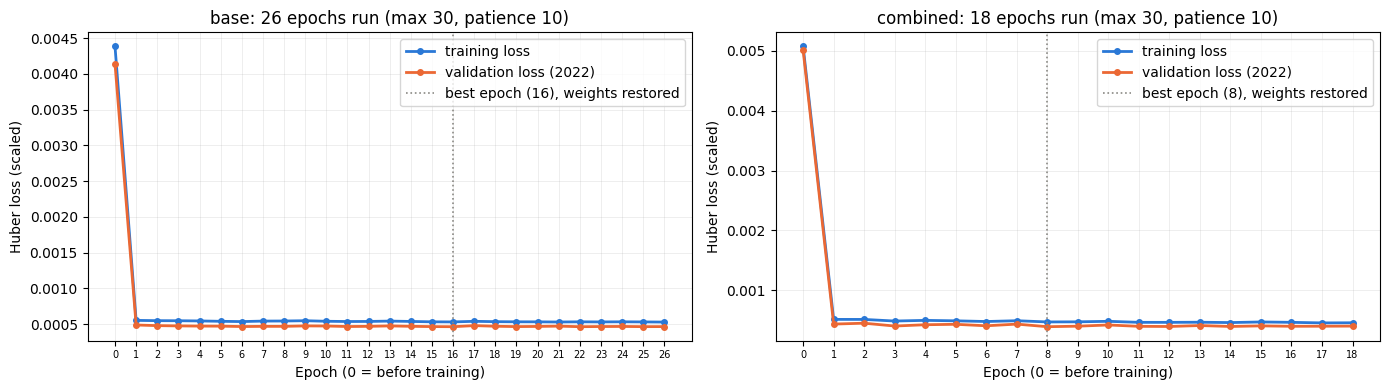

In [14]:
fig, axes = plt.subplots(1, len(runs), figsize=(7 * len(runs), 4))
for ax, (name, run) in zip(np.atleast_1d(axes), runs.items()):
    epochs_axis = np.arange(len(run["history"]["train"]))
    ax.plot(epochs_axis, run["history"]["train"], color=C_MODEL, linewidth=2, marker="o", markersize=4,
            label="training loss")
    ax.plot(epochs_axis, run["history"]["val"], color=C_LAST, linewidth=2, marker="o", markersize=4,
            label="validation loss (2022)")
    ax.axvline(run["best_epoch"], color=C_MUTED, linestyle=":", linewidth=1.2,
               label=f"best epoch ({run['best_epoch']}), weights restored")
    ax.set_xticks(epochs_axis)
    ax.tick_params(axis="x", labelsize=7)
    ax.set_xlabel("Epoch (0 = before training)")
    ax.set_ylabel("Huber loss (scaled)")
    ax.set_title(f"{name}: {len(epochs_axis) - 1} epochs run (max {EPOCHS}, patience {PATIENCE})")
    ax.grid(alpha=0.3, linewidth=0.5)
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Evaluation

### 6.1 Test metrics and the persistence check

The first table compares both feature sets with the naive baselines on the test year (2024). The second reports
RMSE and MAE on **every** partition. `skill` = 1 − model / last value, so positive means the model beats
persistence. Beating persistence on training data but not on validation or test means overfitting.

In [15]:
y_true_test = runs[PLOT_SET]["windows"]["test"]["y_true"]
w_test = runs[PLOT_SET]["windows"]["test"]
test_table = pd.DataFrame({**{f"BiLSTM {name}": compute_metrics(run["windows"]["test"]["y_true"], run["pred"]["test"])
                              for name, run in runs.items()},
                           "Last value": compute_metrics(y_true_test, w_test["last"]),
                           "Moving average (24h)": compute_metrics(y_true_test, w_test["ma24"])}).T[METRIC_COLS]
test_table.index.name = f"{HORIZON}h horizon, test 2024"
test_table.to_csv(os.path.join(OUTPUT_DIR, "test_metrics.csv"))
display(test_table)

persistence_rows = {}
for part_name in ("train", "val", "test"):
    w = runs[PLOT_SET]["windows"][part_name]
    last = compute_metrics(w["y_true"], w["last"])
    for name, run in runs.items():
        mod = compute_metrics(w["y_true"], run["pred"][part_name])
        persistence_rows[(part_name, name)] = {
            "model_RMSE": mod["RMSE"], "last_value_RMSE": last["RMSE"], "RMSE_skill": 1 - mod["RMSE"] / last["RMSE"],
            "model_MAE": mod["MAE"], "last_value_MAE": last["MAE"], "MAE_skill": 1 - mod["MAE"] / last["MAE"],
            "model_bias": mod["Bias"], "n_targets": len(w["y_true"])}
persistence_table = pd.DataFrame(persistence_rows).T
persistence_table.index.names = ["partition", "feature set"]
persistence_table.to_csv(os.path.join(OUTPUT_DIR, "persistence_check.csv"))
display(persistence_table.astype({"n_targets": int}).style
        .format("{:.5f}", subset=["model_RMSE", "last_value_RMSE", "model_MAE", "last_value_MAE"])
        .format("{:+.1%}", subset=["RMSE_skill", "MAE_skill"]).format("{:+.5f}", subset=["model_bias"]))

,MSE,RMSE,MAE,MAPE,SMAPE,RSE,CORR,Bias
"72h horizon, test 2024",,,,,,,,
BiLSTM base,0.001070,0.032705,0.014938,4.443756,4.787333,0.253640,0.869194,-0.003967
BiLSTM combined,0.001081,0.032875,0.012784,3.696842,4.101701,0.256284,0.871121,-0.007064
Last value,0.001119,0.033449,0.017751,5.385685,5.638556,0.265299,0.867586,0.001421
Moving average (24h),0.001186,0.034445,0.019215,5.882274,6.125893,0.281341,0.858350,0.001643


### 6.2 Alignment check on real timestamps

Eight test windows, evenly spaced through 2024: the input window, the target timestamp, the last input value, the
forecast, and the actual `SWC_20` looked up by the target timestamp. The asserts check every scored test window.

In [16]:
w, pred = runs[PLOT_SET]["windows"]["test"], runs[PLOT_SET]["pred"]["test"]
assert ((w["target_time"] - w["end_time"]) == pd.Timedelta(hours=HORIZON)).all()
assert np.allclose(w["last"], df.loc[w["end_time"], TARGET].to_numpy())
assert np.allclose(w["y_true"], df.loc[w["target_time"], TARGET].to_numpy())
pick = np.linspace(0, len(pred) - 1, 8).astype(int)
display(pd.DataFrame({
    "input_start": w["end_time"][pick] - pd.Timedelta(hours=WINDOW_SIZE - 1),
    "input_end": w["end_time"][pick],
    "target_time": w["target_time"][pick],
    "last_value (input_end)": w["last"][pick],
    "forecast": pred[pick],
    "actual (target_time)": df.loc[w["target_time"][pick], TARGET].to_numpy(),
}).round(4))

,input_start,input_end,target_time,last_value (input_end),forecast,actual (target_time)
0,2024-01-01 00:00:00,2024-01-02 23:00:00,2024-01-05 23:00:00,0.378,0.3534,0.367
1,2024-02-21 13:00:00,2024-02-23 12:00:00,2024-02-26 12:00:00,0.343,0.3388,0.339
2,2024-04-13 03:00:00,2024-04-15 02:00:00,2024-04-18 02:00:00,0.249,0.2468,0.246
3,2024-06-03 17:00:00,2024-06-05 16:00:00,2024-06-08 16:00:00,0.345,0.3215,0.305
4,2024-07-25 06:00:00,2024-07-27 05:00:00,2024-07-30 05:00:00,0.379,0.3599,0.368
5,2024-09-14 20:00:00,2024-09-16 19:00:00,2024-09-19 19:00:00,0.306,0.2867,0.287
6,2024-11-05 10:00:00,2024-11-07 09:00:00,2024-11-10 09:00:00,0.200,0.1978,0.198
7,2024-12-27 00:00:00,2024-12-28 23:00:00,2024-12-31 23:00:00,0.200,0.1978,0.197


### 6.3 Test year by month

By target month. Each panel has its own y-axis. The last-value line is the actual series shifted right by
exactly 72 h.

In [17]:
monthly = pd.DataFrame({"actual": w["y_true"], "model": pred, "last_value": w["last"]}, index=w["target_time"])


def month_scores(m):
    mod, last = compute_metrics(m["actual"], m["model"]), compute_metrics(m["actual"], m["last_value"])
    return pd.Series({"model_RMSE": mod["RMSE"], "last_value_RMSE": last["RMSE"], "model_MAE": mod["MAE"],
                      "last_value_MAE": last["MAE"], "model_bias": mod["Bias"], "last_value_bias": last["Bias"]})


by_month = monthly.groupby(monthly.index.to_period("M")).apply(month_scores)
by_month["model_better_MAE"] = by_month["model_MAE"] < by_month["last_value_MAE"]
by_month.index.name = "target month"
by_month.to_csv(os.path.join(OUTPUT_DIR, "test_by_month.csv"))
display(by_month.style.format("{:.4f}", subset=["model_RMSE", "last_value_RMSE", "model_MAE", "last_value_MAE"])
        .format("{:+.4f}", subset=["model_bias", "last_value_bias"]))

,model_RMSE,last_value_RMSE,model_MAE,last_value_MAE,model_bias,last_value_bias,model_better_MAE
target month,,,,,,,
2024-01,0.0181,0.0183,0.0121,0.0132,-0.0039,+0.0018,True
2024-02,0.0137,0.0157,0.0085,0.0113,-0.0031,+0.0021,True
2024-03,0.0055,0.0091,0.0042,0.0070,+0.0023,+0.0065,True
2024-04,0.0164,0.0154,0.0092,0.0099,-0.0060,-0.0031,True
2024-05,0.0366,0.0367,0.0195,0.0248,-0.0126,-0.0007,True
2024-06,0.0572,0.0597,0.0303,0.0434,-0.0180,-0.0010,True
2024-07,0.0608,0.0571,0.0364,0.0451,-0.0272,-0.0049,True
2024-08,0.0038,0.0162,0.0032,0.0143,+0.0030,+0.0143,True
2024-09,0.0610,0.0631,0.0233,0.0359,-0.0153,-0.0019,True


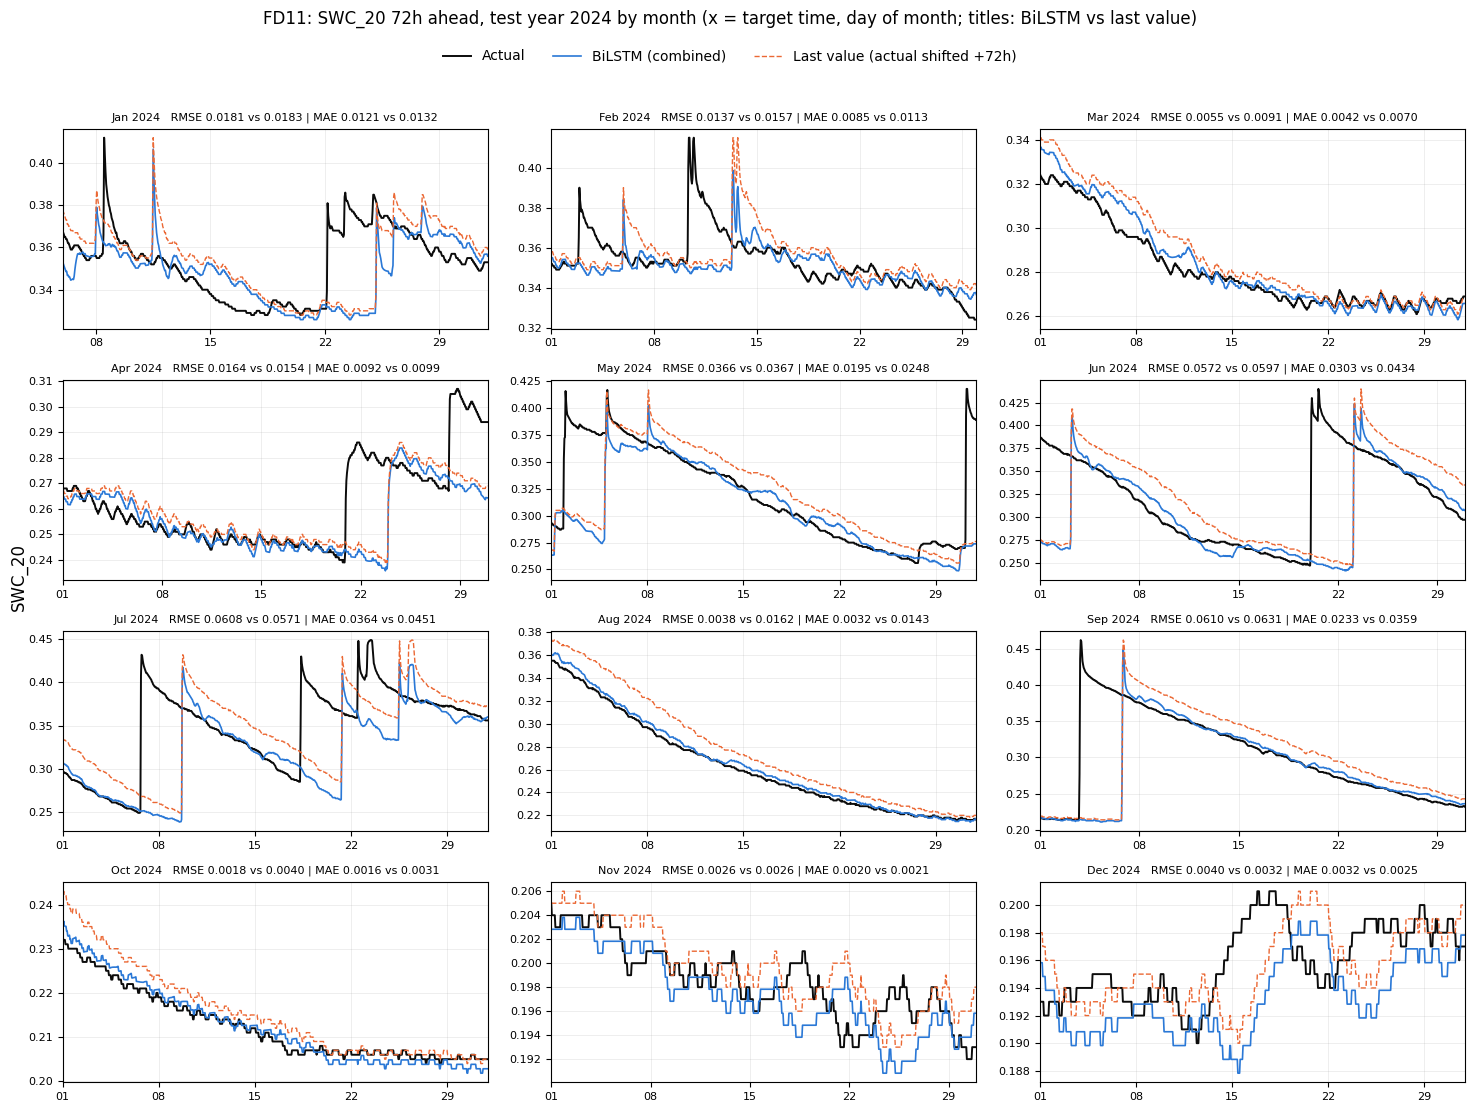

In [18]:
months = monthly.index.to_period("M").unique()
ncols = 3
nrows = int(np.ceil(len(months) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 2.7 * nrows), squeeze=False)
for ax, month in zip(axes.flat, months):
    m = monthly[monthly.index.to_period("M") == month]
    ax.plot(m.index, m["actual"], color=C_ACTUAL, linewidth=1.4, label="Actual")
    ax.plot(m.index, m["model"], color=C_MODEL, linewidth=1.2, label=f"BiLSTM ({PLOT_SET})")
    ax.plot(m.index, m["last_value"], color=C_LAST, linewidth=1.0, linestyle="--",
            label=f"Last value (actual shifted +{HORIZON}h)")
    s = by_month.loc[month]
    ax.set_title(f"{month.strftime('%b %Y')}   RMSE {s['model_RMSE']:.4f} vs {s['last_value_RMSE']:.4f} | "
                 f"MAE {s['model_MAE']:.4f} vs {s['last_value_MAE']:.4f}", fontsize=8)
    ax.set_xlim(m.index.min(), m.index.max())
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22, 29]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d"))
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.3, linewidth=0.5)
for ax in axes.flat[len(months):]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.suptitle(f"{STATION}: SWC_20 {HORIZON}h ahead, test year 2024 by month (x = target time, day of month; "
             f"titles: BiLSTM vs last value)", y=1.025)
fig.supylabel("SWC_20")
plt.tight_layout(rect=(0, 0, 1, 0.975))
plt.show()